# 03 - Hypothesis tests

*Owner: Khalil. Figures `fig06`-`fig08`, report section `05_results_hypotheses.md`.*

The data is already cleaned (see `notebooks/01_data_preparation.ipynb`). Everything below uses the
analysis window `w = window(ev)`: **weekdays 07:00-17:59**, when buses are scheduled every 10 minutes.

| Hypothesis | Statement | Test |
|---|---|---|
| **H1** | Buses with a longer headway behind the bus ahead carry more passengers | Spearman + Kruskal-Wallis |
| **H2** | More boardings/alightings make the bus dwell longer at the stop | OLS regression |
| **H3** | Headways get more irregular further along the route | Spearman on CV by stop |

Significance level: **alpha = 0.05**.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from project import (load_events, window, new_fig, finish, save,
                     COLORS, SERIES, SOURCE_NOTE)

ALPHA = 0.05


# Format a p-value; SciPy returns exactly 0.0 when the p-value underflows.
def pfmt(p):
    return f"= {p:.3g}" if p > 0 else "< 1e-308 (underflow)"


ev = load_events()
w = window(ev)

print(f"all stop events        : {len(ev):,}")
print(f"analysis window (w)    : {len(w):,}")
print(f"service days in window : {w.service_day.nunique()}")
print(f"alpha                  : {ALPHA}")

all stop events        : 229,414
analysis window (w)    : 126,070
service days in window : 131
alpha                  : 0.05


---
## H1 - Longer headway -> more passengers on board

- **H0:** passenger load does not change with the headway behind the bus ahead.
- **H1:** buses with a longer headway carry more passengers.

Rows used: window rows with a valid `headway_s` (terminal stops, first bus of the day and
unverified gaps are already excluded by the cleaning step).

In [2]:
h1 = w[w.headway_s.notna()].copy()
h1["headway_min"] = h1.headway_s / 60

EDGES = [0, 5, 10, 15, 20, np.inf]
LABELS = ["0-5", "5-10", "10-15", "15-20", "20+"]
h1["headway_group"] = pd.cut(h1.headway_min, bins=EDGES, labels=LABELS, right=False)

g = h1.groupby("headway_group", observed=True).max_load
h1_stats = pd.DataFrame({
    "n": g.size(),
    "mean_load": g.mean().round(2),
    "median_load": g.median(),
    "q25": g.quantile(0.25),
    "q75": g.quantile(0.75),
})

print(f"rows with a valid headway: {len(h1):,}")
print(f"headway: median {h1.headway_min.median():.1f} min, mean {h1.headway_min.mean():.1f} min")
print()
print("Mean passengers on board by headway group")
print(h1_stats.to_string())

rows with a valid headway: 51,437
headway: median 11.0 min, mean 11.9 min

Mean passengers on board by headway group
                   n  mean_load  median_load   q25   q75
headway_group                                           
0-5             6549       9.08          8.0   5.0  12.0
5-10           15297      11.00         10.0   6.0  14.0
10-15          15693      13.42         13.0   8.0  18.0
15-20           8547      15.84         15.0  10.0  21.0
20+             5351      17.85         17.0  11.0  24.0


In [3]:
# --- Test 1: Spearman rank correlation (headway vs load) ---
rho, p_rho = stats.spearmanr(h1.headway_s, h1.max_load)

# --- Test 2: Kruskal-Wallis across the five headway groups ---
groups = [grp.max_load.values for _, grp in h1.groupby("headway_group", observed=True)]
H, p_kw = stats.kruskal(*groups)

print("H1 test results")
print(f"  Spearman rho    = {rho:.3f}   p {pfmt(p_rho)}   (n = {len(h1):,})")
print(f"  Kruskal-Wallis H = {H:.1f}   df = {len(groups) - 1}   p {pfmt(p_kw)}")
print(f"  mean load: {h1_stats.mean_load.iloc[0]:.1f} passengers in the 0-5 min group "
      f"-> {h1_stats.mean_load.iloc[-1]:.1f} in the 20+ min group")
print(f"  reject H0 (Spearman):       {p_rho < ALPHA}")
print(f"  reject H0 (Kruskal-Wallis): {p_kw < ALPHA}")

H1 test results
  Spearman rho    = 0.349   p < 1e-308 (underflow)   (n = 51,437)
  Kruskal-Wallis H = 5883.4   df = 4   p < 1e-308 (underflow)
  mean load: 9.1 passengers in the 0-5 min group -> 17.9 in the 20+ min group
  reject H0 (Spearman):       True
  reject H0 (Kruskal-Wallis): True


C:\Users\Khalil\Desktop\IDSA\ELE-IDSA-PROJECT-1\figures\fig06_h1_load_vs_headway.png


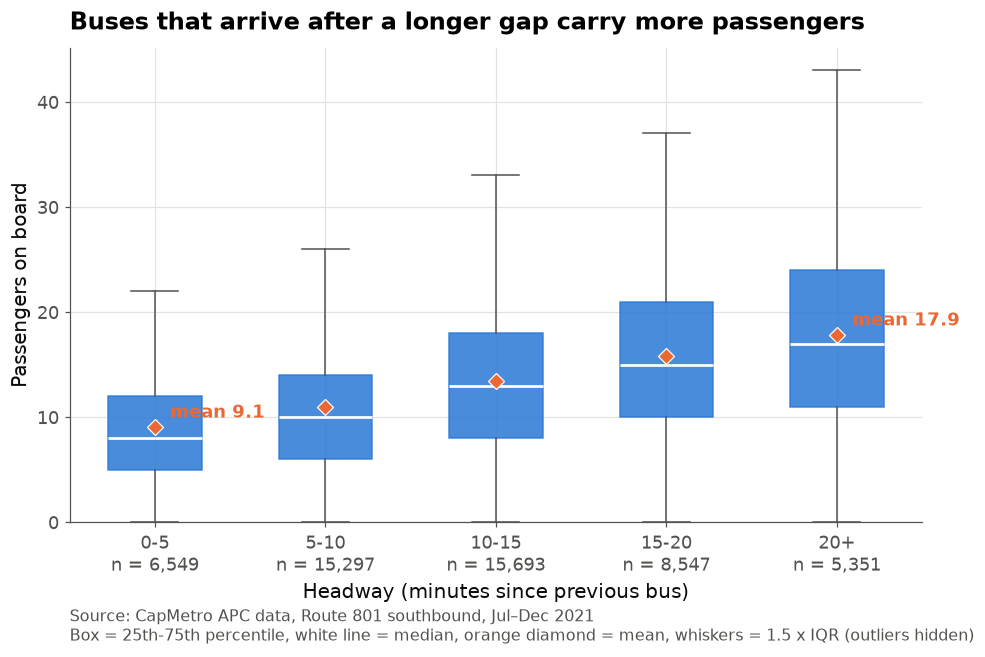

In [4]:
fig, ax = new_fig()

data = [h1.loc[h1.headway_group == lab, "max_load"].values for lab in LABELS]
bp = ax.boxplot(
    data, showfliers=False, widths=0.55, patch_artist=True, showmeans=True,
    medianprops=dict(color="white", linewidth=1.8),
    boxprops=dict(facecolor=COLORS["blue"], edgecolor=COLORS["blue"], alpha=0.85),
    whiskerprops=dict(color=COLORS["muted"]),
    capprops=dict(color=COLORS["muted"]),
    meanprops=dict(marker="D", markersize=7, markerfacecolor=COLORS["orange"],
                   markeredgecolor="white", markeredgewidth=0.8),
)

# n under each box label
ax.set_xticks(range(1, len(LABELS) + 1))
ax.set_xticklabels([f"{lab}\nn = {h1_stats.n[lab]:,}" for lab in LABELS])

# label only the first and last group mean
for i in (0, len(LABELS) - 1):
    m = h1_stats.mean_load.iloc[i]
    ax.annotate(f"mean {m:.1f}", xy=(i + 1, m), xytext=(10, 6), textcoords="offset points",
                color=COLORS["orange"], fontsize=11.5, fontweight="bold")

ax.set_ylim(0, None)

finish(ax,
       "Buses that arrive after a longer gap carry more passengers",
       "Headway (minutes since previous bus)",
       "Passengers on board",
       note=SOURCE_NOTE + "\n" + "Box = 25th-75th percentile, white line = median, "
            "orange diamond = mean, whiskers = 1.5 x IQR (outliers hidden)")
print(save(fig, "fig06_h1_load_vs_headway"))
plt.show()

---
## H2 - More boardings and alightings -> longer dwell time

- **H0:** dwell time does not depend on the number of passengers boarding or alighting.
- **H2:** dwell time grows with boardings (`ons`) and alightings (`offs`).

Rows used: non-terminal window rows (`is_terminal == False`); terminal dwell times are layovers
and were already removed during cleaning.

In [5]:
h2 = w[w.is_terminal == False].copy()

model = smf.ols("dwell_time ~ ons + offs", data=h2).fit()

print(f"rows used: {len(h2):,} non-terminal stop events")
print()
print(model.summary().tables[1])
print()
print(f"R-squared          = {model.rsquared:.3f}")
print(f"adj. R-squared     = {model.rsquared_adj:.3f}")
print(f"F({int(model.df_model)}, {int(model.df_resid)}) = {model.fvalue:.1f}   p {pfmt(model.f_pvalue)}")
print()
for name in ("Intercept", "ons", "offs"):
    print(f"  {name:<10} b = {model.params[name]:.3f} s   "
          f"t = {model.tvalues[name]:.1f}   p {pfmt(model.pvalues[name])}   "
          f"95% CI [{model.conf_int().loc[name, 0]:.3f}, {model.conf_int().loc[name, 1]:.3f}]")
print()
print(f"  reject H0 for ons : {model.pvalues['ons'] < ALPHA}")
print(f"  reject H0 for offs: {model.pvalues['offs'] < ALPHA}")
print(f"  mean dwell time   : {h2.dwell_time.mean():.1f} s (median {h2.dwell_time.median():.1f} s)")
print(f"  mean offs         : {h2.offs.mean():.2f} passengers")

rows used: 116,697 non-terminal stop events

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.7879      0.170     75.202      0.000      12.455      13.121
ons            6.9129      0.053    130.655      0.000       6.809       7.017
offs           3.6516      0.056     65.649      0.000       3.543       3.761

R-squared          = 0.180
adj. R-squared     = 0.180
F(2, 116694) = 12777.0   p < 1e-308 (underflow)

  Intercept  b = 12.788 s   t = 75.2   p < 1e-308 (underflow)   95% CI [12.455, 13.121]
  ons        b = 6.913 s   t = 130.7   p < 1e-308 (underflow)   95% CI [6.809, 7.017]
  offs       b = 3.652 s   t = 65.6   p < 1e-308 (underflow)   95% CI [3.543, 3.761]

  reject H0 for ons : True
  reject H0 for offs: True
  mean dwell time   : 30.9 s (median 18.0 s)


  mean offs         : 1.69 passengers


In [6]:
ONS_MAX = 20
prof = (h2[h2.ons <= ONS_MAX]
        .groupby("ons")
        .dwell_time
        .agg(n="size", mean="mean", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
        .reset_index())

offs_mean = h2.offs.mean()
xx = np.arange(0, ONS_MAX + 1)
fit = model.params["Intercept"] + model.params["ons"] * xx + model.params["offs"] * offs_mean

print("Observed mean dwell time by boardings (ons)")
print(prof.round(2).to_string(index=False))
print()
print(f"fitted line (offs held at its mean of {offs_mean:.2f}): "
      f"dwell = {model.params['Intercept'] + model.params['offs'] * offs_mean:.1f} "
      f"+ {model.params['ons']:.2f} x ons")
print(f"  0 boarding  -> fitted {fit[0]:.1f} s (observed mean {prof.loc[prof.ons == 0, 'mean'].iloc[0]:.1f} s)")
print(f"  20 boarding -> fitted {fit[-1]:.1f} s (observed mean {prof.loc[prof.ons == ONS_MAX, 'mean'].iloc[0]:.1f} s)")

Observed mean dwell time by boardings (ons)
 ons     n   mean   q25    q75
 0.0 39170  16.93 11.00  17.00
 1.0 33618  22.89 11.00  22.00
 2.0 17444  34.43 16.00  34.00
 3.0  9685  44.71 20.00  45.00
 4.0  5860  52.84 23.00  54.00
 5.0  3655  62.00 26.00  63.00
 6.0  2230  70.47 30.00  73.00
 7.0  1544  72.75 32.00  80.00
 8.0  1024  86.51 34.00  90.00
 9.0   651  91.36 39.00  97.00
10.0   500  87.78 38.75  98.25
11.0   332  89.64 41.00 109.25
12.0   240 107.86 50.00 118.75
13.0   189 104.61 52.00 114.00
14.0   137  96.18 43.00 106.00
15.0   100 122.06 47.00 124.25
16.0    69 105.96 39.00 139.00
17.0    44 128.18 65.75 147.75
18.0    41 140.61 65.00 186.00
19.0    33 103.14 54.00 106.00
20.0    23 111.78 49.50 135.00

fitted line (offs held at its mean of 1.69): dwell = 19.0 + 6.91 x ons
  0 boarding  -> fitted 19.0 s (observed mean 16.9 s)
  20 boarding -> fitted 157.2 s (observed mean 111.8 s)


C:\Users\Khalil\Desktop\IDSA\ELE-IDSA-PROJECT-1\figures\fig07_h2_dwell_vs_boardings.png


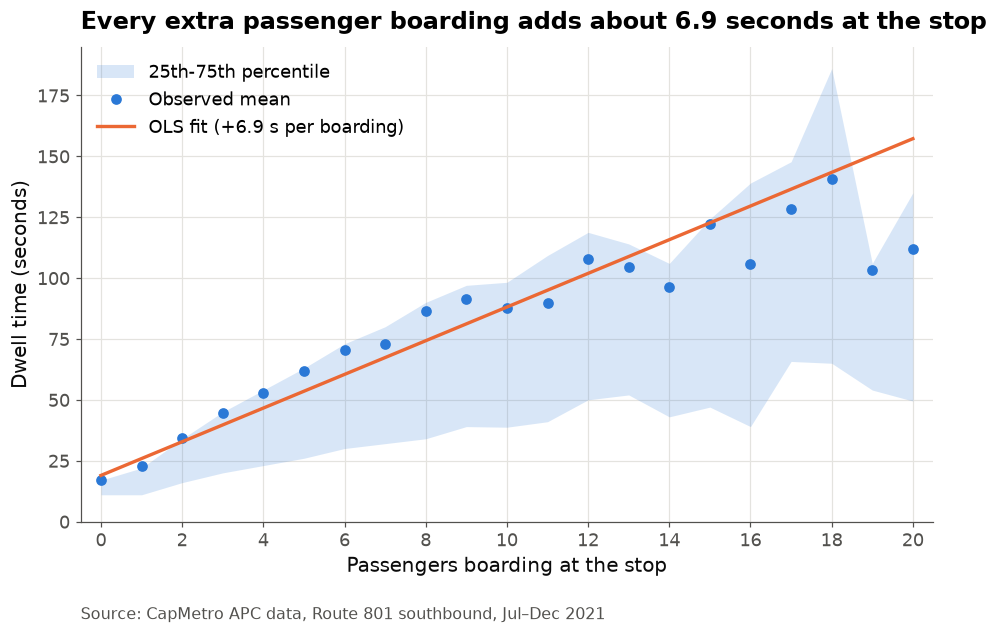

In [7]:
fig, ax = new_fig()

ax.fill_between(prof.ons, prof.q25, prof.q75, color=COLORS["blue"], alpha=0.18,
                linewidth=0, label="25th-75th percentile")
ax.plot(prof.ons, prof["mean"], "o", color=COLORS["blue"], markersize=6,
        label="Observed mean")
ax.plot(xx, fit, "-", color=COLORS["orange"], linewidth=2.2,
        label=f"OLS fit (+{model.params['ons']:.1f} s per boarding)")

ax.legend(loc="upper left")
ax.set_xticks(range(0, ONS_MAX + 1, 2))
ax.set_xlim(-0.5, ONS_MAX + 0.5)
ax.set_ylim(0, None)

finish(ax,
       "Every extra passenger boarding adds about "
       f"{model.params['ons']:.1f} seconds at the stop",
       "Passengers boarding at the stop",
       "Dwell time (seconds)",
       note=SOURCE_NOTE)
print(save(fig, "fig07_h2_dwell_vs_boardings"))
plt.show()

---
## H3 - Headways get more irregular along the route

- **H0:** headway irregularity does not change with position along the route.
- **H3:** irregularity (coefficient of variation, CV = std / mean of headway) grows with `stop_order`.

For every `service_day` x `stop_order` with **at least 3 valid headways** we compute the CV, then
average those daily CVs per stop. Stops 1 and 29 are terminals and have no valid headways, so the
chart covers stops 2-28.

In [8]:
h3 = w[w.headway_s.notna()].copy()

daily = (h3.groupby(["service_day", "stop_order"])
           .headway_s
           .agg(n="size", mean="mean", std="std")
           .reset_index())
daily = daily[daily.n >= 3].copy()
daily["cv"] = daily["std"] / daily["mean"]

by_stop = (daily.groupby("stop_order")
                .cv
                .agg(days="size", mean_cv="mean",
                     q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
                .reset_index())
by_stop = by_stop[(by_stop.stop_order >= 2) & (by_stop.stop_order <= 28)]

print(f"day x stop cells with >= 3 headways: {len(daily):,}")
print(f"stops covered: {by_stop.stop_order.min()}-{by_stop.stop_order.max()} "
      f"({len(by_stop)} stops), {daily.service_day.nunique()} service days")
print()
print(by_stop.round(3).to_string(index=False))

day x stop cells with >= 3 headways: 3,382
stops covered: 2-28 (27 stops), 128 service days

 stop_order  days  mean_cv   q25   q75
          2   120    0.387 0.278 0.503
          3   128    0.416 0.341 0.483
          4   128    0.415 0.329 0.485
          5   128    0.444 0.384 0.495
          6   128    0.414 0.338 0.473
          7   128    0.487 0.424 0.538
          8   128    0.508 0.441 0.563
          9   127    0.494 0.413 0.581
         10   127    0.471 0.382 0.551
         11   127    0.513 0.445 0.565
         12   126    0.516 0.439 0.595
         13   122    0.537 0.428 0.630
         14   128    0.537 0.464 0.595
         15   128    0.559 0.510 0.600
         16   128    0.547 0.459 0.651
         17    98    0.530 0.394 0.662
         18   128    0.572 0.478 0.648
         19   128    0.578 0.520 0.630
         20   127    0.569 0.471 0.646
         21   121    0.542 0.450 0.637
         22   128    0.587 0.509 0.652
         23   127    0.583 0.470 0.697
         2

In [9]:
rho3, p3 = stats.spearmanr(by_stop.stop_order, by_stop.mean_cv)

first_cv = by_stop.mean_cv.iloc[0]
last_cv = by_stop.mean_cv.iloc[-1]
peak = by_stop.loc[by_stop.mean_cv.idxmax()]

print("H3 test results")
print(f"  Spearman rho = {rho3:.3f}   p {pfmt(p3)}   (n = {len(by_stop)} stops)")
print(f"  mean CV: {first_cv:.3f} at stop {int(by_stop.stop_order.iloc[0])} "
      f"-> {last_cv:.3f} at stop {int(by_stop.stop_order.iloc[-1])} "
      f"(+{100 * (last_cv / first_cv - 1):.0f}%)")
print(f"  highest mean CV: {peak.mean_cv:.3f} at stop {int(peak.stop_order)}")
print(f"  reject H0: {p3 < ALPHA}")

H3 test results
  Spearman rho = 0.955   p = 9.33e-15   (n = 27 stops)
  mean CV: 0.387 at stop 2 -> 0.583 at stop 28 (+51%)
  highest mean CV: 0.622 at stop 27
  reject H0: True


C:\Users\Khalil\Desktop\IDSA\ELE-IDSA-PROJECT-1\figures\fig08_h3_headway_cv_by_stop.png


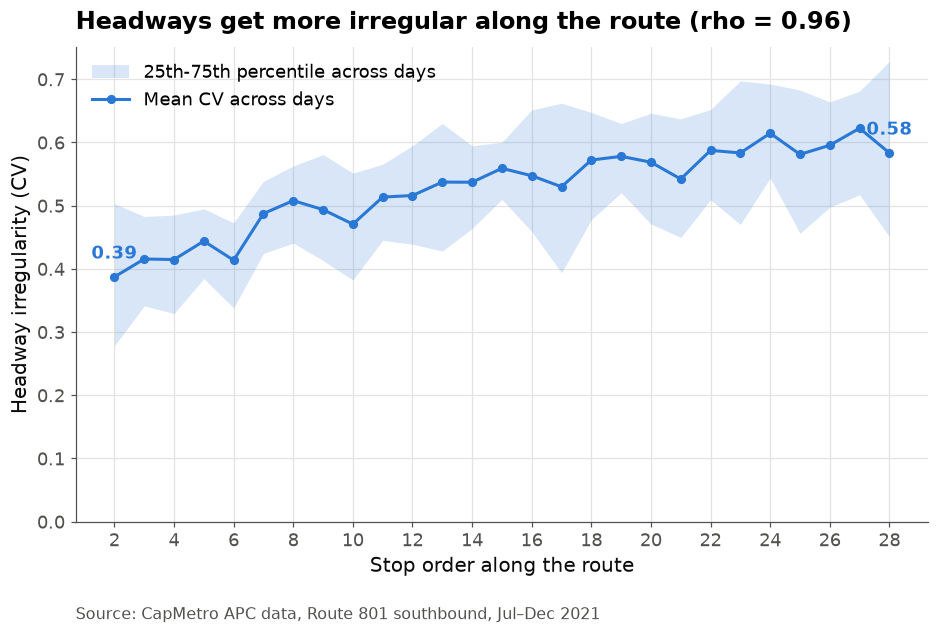

In [10]:
fig, ax = new_fig()

ax.fill_between(by_stop.stop_order, by_stop.q25, by_stop.q75, color=COLORS["blue"],
                alpha=0.18, linewidth=0, label="25th-75th percentile across days")
ax.plot(by_stop.stop_order, by_stop.mean_cv, "-o", color=COLORS["blue"], markersize=5,
        label="Mean CV across days")

for x, y, txt in ((by_stop.stop_order.iloc[0], first_cv, f"{first_cv:.2f}"),
                  (by_stop.stop_order.iloc[-1], last_cv, f"{last_cv:.2f}")):
    ax.annotate(txt, xy=(x, y), xytext=(0, 12), textcoords="offset points",
                ha="center", color=COLORS["blue"], fontsize=11.5, fontweight="bold")

ax.legend(loc="upper left")
ax.set_xticks(range(2, 29, 2))
ax.set_ylim(0, None)

finish(ax,
       f"Headways get more irregular along the route (rho = {rho3:.2f})",
       "Stop order along the route",
       "Headway irregularity (CV)",
       note=SOURCE_NOTE)
print(save(fig, "fig08_h3_headway_cv_by_stop"))
plt.show()

---
## Summary of every statistic used in the report text

In [11]:
print(f"alpha = {ALPHA}\n")

print("H1  longer headway -> more passengers")
print(f"  n rows                 : {len(h1):,}")
print(f"  mean load 0-5 min      : {h1_stats.mean_load.iloc[0]:.1f} passengers (n = {h1_stats.n.iloc[0]:,})")
print(f"  mean load 20+ min      : {h1_stats.mean_load.iloc[-1]:.1f} passengers (n = {h1_stats.n.iloc[-1]:,})")
print(f"  median load 0-5 / 20+  : {h1_stats.median_load.iloc[0]:.0f} / {h1_stats.median_load.iloc[-1]:.0f}")
print(f"  Spearman rho           : {rho:.3f} (p {pfmt(p_rho)})")
print(f"  Kruskal-Wallis H       : {H:.1f}, df = {len(groups) - 1} (p {pfmt(p_kw)})")
print(f"  decision               : {'reject H0' if p_rho < ALPHA and p_kw < ALPHA else 'fail to reject H0'}\n")

print("H2  more boardings -> longer dwell")
print(f"  n rows                 : {len(h2):,}")
print(f"  b_ons                  : {model.params['ons']:.3f} s per boarding (p {pfmt(model.pvalues['ons'])})")
print(f"  b_offs                 : {model.params['offs']:.3f} s per alighting (p {pfmt(model.pvalues['offs'])})")
print(f"  intercept              : {model.params['Intercept']:.3f} s")
print(f"  R-squared              : {model.rsquared:.3f}")
print(f"  mean dwell time        : {h2.dwell_time.mean():.1f} s")
print(f"  fitted dwell 0 -> 20 ons: {fit[0]:.1f} s -> {fit[-1]:.1f} s")
print(f"  decision               : {'reject H0' if model.pvalues['ons'] < ALPHA else 'fail to reject H0'}\n")

print("H3  irregularity grows along the route")
print(f"  stops                  : {int(by_stop.stop_order.min())}-{int(by_stop.stop_order.max())} ({len(by_stop)} stops)")
print(f"  day x stop cells       : {len(daily):,}")
print(f"  mean CV stop 2 -> 28   : {first_cv:.3f} -> {last_cv:.3f}")
print(f"  highest mean CV        : {peak.mean_cv:.3f} at stop {int(peak.stop_order)}")
print(f"  Spearman rho           : {rho3:.3f} (p {pfmt(p3)})")
print(f"  decision               : {'reject H0' if p3 < ALPHA else 'fail to reject H0'}")

alpha = 0.05

H1  longer headway -> more passengers
  n rows                 : 51,437
  mean load 0-5 min      : 9.1 passengers (n = 6,549)
  mean load 20+ min      : 17.9 passengers (n = 5,351)
  median load 0-5 / 20+  : 8 / 17
  Spearman rho           : 0.349 (p < 1e-308 (underflow))
  Kruskal-Wallis H       : 5883.4, df = 4 (p < 1e-308 (underflow))
  decision               : reject H0

H2  more boardings -> longer dwell
  n rows                 : 116,697
  b_ons                  : 6.913 s per boarding (p < 1e-308 (underflow))
  b_offs                 : 3.652 s per alighting (p < 1e-308 (underflow))
  intercept              : 12.788 s
  R-squared              : 0.180
  mean dwell time        : 30.9 s
  fitted dwell 0 -> 20 ons: 19.0 s -> 157.2 s
  decision               : reject H0

H3  irregularity grows along the route
  stops                  : 2-28 (27 stops)
  day x stop cells       : 3,382
  mean CV stop 2 -> 28   : 0.387 -> 0.583
  highest mean CV        : 0.622 at stop 27
  S